In [1]:
# If using this notebook in Google Colab, install python-control
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    %pip install -q control==0.10.2

In [3]:
import numpy as np
import control as ct
import matplotlib.pyplot as plt
from scipy import signal

Time Vector

In [4]:
t = np.linspace(0, 40, 4001)

Exact Original Process

In [5]:
# G(s) = 4(1 - 1.5s)e^(-0.5s) /
#        [(6s+1)(s+1)(0.5s+1)]

num_exact = [-6, 4]
den_exact = [3, 9.5, 7.5, 1]

sys_exact = signal.TransferFunction(num_exact, den_exact)

# Calculate response without delay
t_shift = t[t >= 0.5] - 0.5
_, y_rational = signal.step(sys_exact, T=t_shift)

# Apply the physical 0.5 min delay
y_exact = np.zeros_like(t)
y_exact[t >= 0.5] = y_rational

Taylor FOPTD (exact delay)

In [6]:
# G(s) = 4e^(-3.5s)/(6s+1)
# --------------------------------------------------

y_taylor = np.zeros_like(t)
mask = t >= 3.5
y_taylor[mask] = 4 * (
    1 - np.exp(-(t[mask] - 3.5) / 6)
)

Skogestad half-rule FOPTD (exact delay)

In [7]:
y_half = np.zeros_like(t)
mask = t >= 3.0
y_half[mask] = 4 * (
    1 - np.exp(-(t[mask] - 3.0) / 6.5)
)

Half-rule with [1/1] Pade

In [8]:
num_pade1 = [-6, 4]
den_pade1 = [9.75, 8, 1]

sys_pade1 = signal.TransferFunction(num_pade1, den_pade1)
_, y_pade1 = signal.step(sys_pade1, T=t)


Half-rule with [2/2] Pade

In [9]:
num_pade2 = [3, -6, 4]
den_pade2 = [4.875, 10.5, 8, 1]

sys_pade2 = signal.TransferFunction(num_pade2, den_pade2)
_, y_pade2 = signal.step(sys_pade2, T=t)

Plot

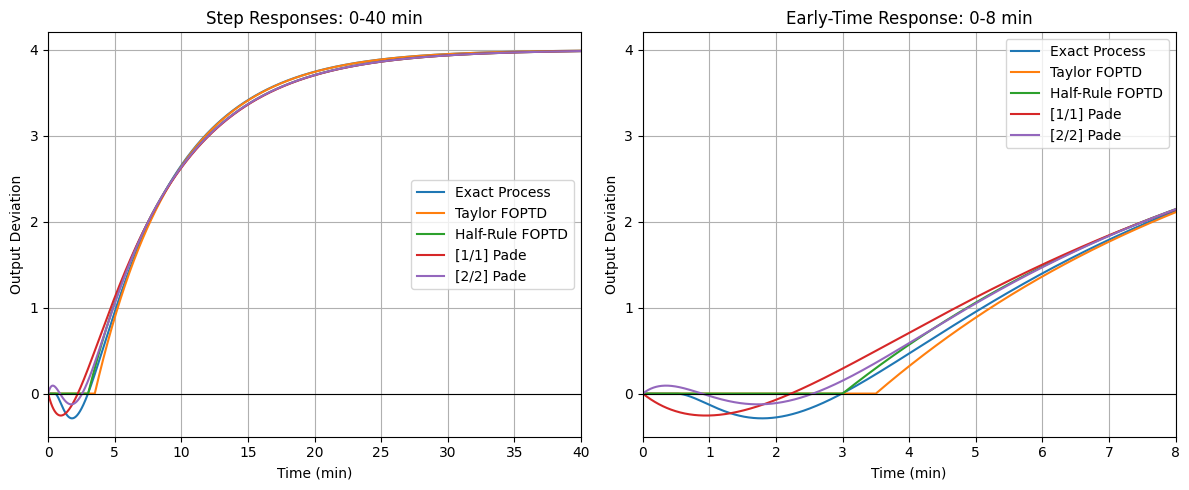

In [11]:
plt.figure(figsize=(12, 5))

# Full-time response
plt.subplot(1, 2, 1)

plt.plot(t, y_exact, label="Exact Process")
plt.plot(t, y_taylor, label="Taylor FOPTD")
plt.plot(t, y_half, label="Half-Rule FOPTD")
plt.plot(t, y_pade1, label="[1/1] Pade")
plt.plot(t, y_pade2, label="[2/2] Pade")

plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel("Time (min)")
plt.ylabel("Output Deviation")
plt.title("Step Responses: 0-40 min")
plt.xlim(0, 40)
plt.grid(True)
plt.legend()

# Early-time response
plt.subplot(1, 2, 2)

plt.plot(t, y_exact, label="Exact Process")
plt.plot(t, y_taylor, label="Taylor FOPTD")
plt.plot(t, y_half, label="Half-Rule FOPTD")
plt.plot(t, y_pade1, label="[1/1] Pade")
plt.plot(t, y_pade2, label="[2/2] Pade")

plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel("Time (min)")
plt.ylabel("Output Deviation")
plt.title("Early-Time Response: 0-8 min")
plt.xlim(0, 8)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()